# Implementation of `txt2biocrnpyler` to Simulate Transcription-Factor-Based Biosensors

**Installing and Initializing Modules**: See the [README](https://github.com/usnistgov/txt2biocrnpyler/blob/master/README.md) documentation for additional details.

This notebook illustrates how to simulate a transcription-factor-based biosensor from *Programming Cell-free Biosensors with DNA Strand Displacement Circuits* ([Jung et al., *Nature Chemical Biology* 2022](https://www.nature.com/articles/s41589-021-00962-9)) in BioSCRAPE using `txt2biocrnpyler` to obtain an SBML `.xml` file from the provided ODEs. 

The workflow starts by converting the transcription-factor-based biosensor chemical reactions to `txt2biocrnpyler`. The generated `.xml` file is downloaded and can then be simulated as-is using BioSCRAPE, or seamlessly modified to include upstream and downstream reactions prior to simulation.

In the cells below, we demonstrate how to load the directly downloaded `.xml` file into **BioSCRAPE**. Once loaded, the model can be simulated as-is or seamlessly expanded by appending new upstream and downstream reactions directly to the network prior to simulation.

**Figure 3 Simulations:**
* [Figure 3B: Base Model Simulation](#Model-0:-Base-Model-Simulation)
* [Figure 3C: Extension with Downstream Translation](#Model-1:-Extension-with-Downstream-Translation)
* [Extension with Downstream Translation](#Model-2:-Extension-with-Degradation-of-Invading-RNA-Strand)
* [Figure 3D: Extension with Upstream LacI Regulation](#Model-3:-Extension-with-Upstream-LacI-Regulation)

>**Note:** Expanding the model directly within BioSCRAPE, as shown here, serves as an alternative method to manually editing the BioCRNpyler Python script generated by `txt2biocrnpyler`.

## Global variables, definitions, and dependencies

In [1]:
#General
import numpy as np

#From bioscrape
from bioscrape.simulator import py_simulate_model
from bioscrape.types import Model
import matplotlib.pyplot as plt
from pathlib import Path

# Get base directory for BioCRNpyler scripts
directory = Path.cwd()
for p in [directory, *directory.parents]:
    if p.name == 'TMSE_BioCRNpyler_Library':
        base_dir = p
        break

# Directory for Figures and Data
figs_dir = (base_dir / 'figures').as_posix()
data_dir = (base_dir / 'data').as_posix()
models_dir = (base_dir / 'models').as_posix()

In [2]:
# Simulate all models - example for 12 hours
timepoints = np.linspace(0,12,1001)*3600 

# Set a global default size for plots
plt.rcParams["figure.figsize"] = (8.27, 6)

#Definition to un-nest lists that will be created by models
def flatten(t):
    return [item for sublist in t for item in sublist]

# Set a global default size for plots
font = 'MS Reference Sans Serif'
plt.rcParams["svg.fonttype"] = "none"
plt.rcParams['font.sans-serif'] = ['MS Reference Sans Serif']

# Plotting format
def FormatPlot(ylabel, fig_name, ymin = -0.25, ymax = 25):
    fs = 22
    plt.ylabel(ylabel,fontsize=fs)
    plt.xlabel('Time (h)',fontsize=fs)
    plt.xlabel('Time (h)',fontsize=22)
    plt.ylim(ymin,ymax)
    plt.xlim(0,12)

    plt.ylim(ymin,ymax)
    plt.xticks(fontsize=fs)
    plt.yticks(fontsize=fs)
    plt.legend(title="[tet]", frameon=False)

    # Save plot as svg
    plt.savefig(f'{figs_dir}/SI_{fig_name}.svg')

colors=['#b3cde3','#8c96c6','#8856a7', '#810f7c']

# Model 0: Base Model Simulation

c:\Users\zej1\AppData\Local\miniforge3\envs\ctRSD_models\Lib\site-packages\bioscrape\sbmlutil.py:183: UserWarning: SBML model contains reversible reaction!
Please check rate expressions and ensure they are non-negative before doing stochastic simulations.
  warnings.warn('SBML model contains reversible reaction!\n' +
c:\Users\zej1\AppData\Local\miniforge3\envs\ctRSD_models\Lib\site-packages\bioscrape\sbmlutil.py:56: UserWarning: Compartments, UnitDefintions, Events, and some other SBML model components are not recognized by bioscrape. Refer to the bioscrape wiki for more information.
  warnings.warn('Compartments, UnitDefintions, Events, and some other SBML model components are not recognized by bioscrape. ' +


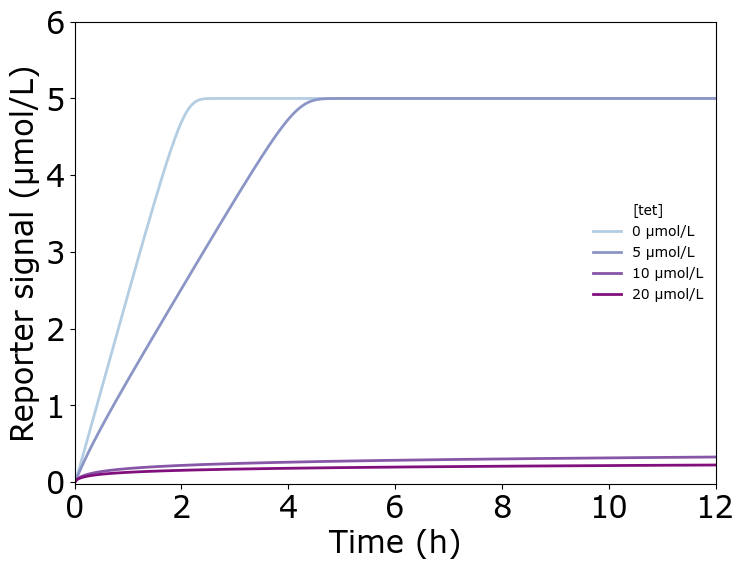

In [3]:
#Get model
filename = 'jung2022_txt2biocrnpyler_sbml'
m = Model(sbml_filename = f'{models_dir}/{filename}.xml')

for tet_conc, color in zip([0, 5, 10, 20],colors):
    m.set_species({"tet":tet_conc})

    R = py_simulate_model(Model  = m, timepoints = timepoints)

    # Results are in a Pandas Dictionary and can be accessed via string-names of species
    plt.plot(R['time']/3600, R['SD'], color=color, linewidth = 2, label = f"{tet_conc} μmol/L")

FormatPlot('Reporter signal (μmol/L)', 'BioSCRAPE_NOTgate', ymin = -0.02, ymax=6)

# Model 1: Extension with Downstream Translation

**Model 1= Model 0 + G{1, GFP} and TL**

Added reactions:
1. $D_{gate}$ + RNAP $\leftrightarrow$ $RD_{gate}$ 
2. $RD_{gate}$  $\rightarrow$ $D_{gate}$ + RNAP + Gate{1,GFP}$_{RNA}$
3. Gate{1,GFP}$_{RNA}$ + $InvR_v$ $\rightarrow$ $GFP_{RNA}$
4. $GFP_{RNA}$ $\rightarrow$ $GFP_{protein}$


***Note:** To simplify the modeling process, we took a shortcut by reusing existing species. Specifically, we effectively used R{1} in place of G{1,GFP} and translated from the product RNA `Q`.*

In [4]:
# Orignal model
m = Model(sbml_filename = f'{models_dir}/{filename}.xml')
m.set_species({"RQ": 0}) # Setting orignal reporter to 0, before manually replacing with Gate(1,GFP}

# New reactions
# transcription
m.create_reaction(["D_GFPgate", "RNAP"], ["RD_gate"], "massaction", {"k":"k_bind"})
m.create_reaction(["RD_gate"], ["D_GFPgate", "RNAP"], "massaction", {"k":"k_unbind"})
m.create_reaction(['RD_gate'],["D_GFPgate", "RNAP", "RD_GFPgate"], "massaction", {"k":"k_m_unreg"})

# strand displacement
m.create_reaction(["RD_GFPgate", "InvR_U"], ['RNA_GFP'], "massaction", {"k":"k_SD_mis"})

# translation
m.create_parameter("ktl", .0001)
m.create_reaction(["RNA_GFP"], ['RNA_GFP', 'GFP'], "massaction", {"k":"ktl"})

m.set_species({"D_GFPgate": 0.025}) # Setting orignal reporter to 0

c:\Users\zej1\AppData\Local\miniforge3\envs\ctRSD_models\Lib\site-packages\bioscrape\sbmlutil.py:183: UserWarning: SBML model contains reversible reaction!
Please check rate expressions and ensure they are non-negative before doing stochastic simulations.
  warnings.warn('SBML model contains reversible reaction!\n' +
c:\Users\zej1\AppData\Local\miniforge3\envs\ctRSD_models\Lib\site-packages\bioscrape\sbmlutil.py:56: UserWarning: Compartments, UnitDefintions, Events, and some other SBML model components are not recognized by bioscrape. Refer to the bioscrape wiki for more information.
  warnings.warn('Compartments, UnitDefintions, Events, and some other SBML model components are not recognized by bioscrape. ' +


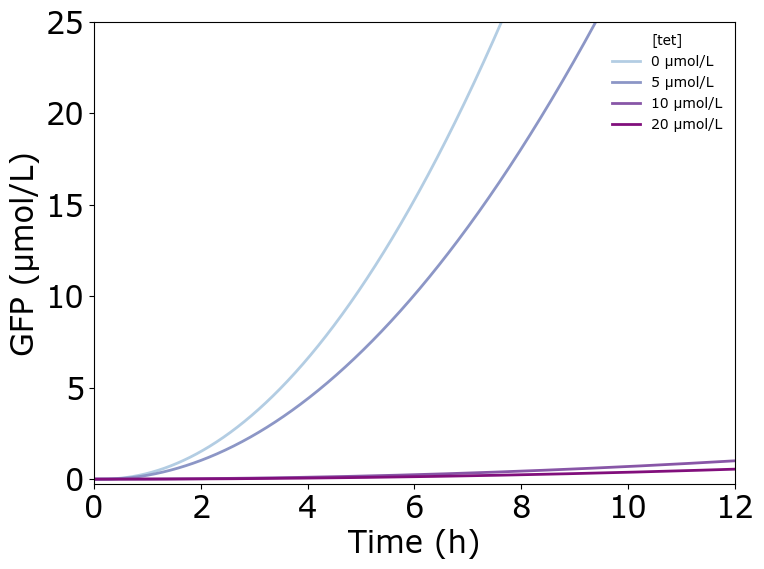

In [5]:
# Initialize empty lists to collect handles and labels
handles, labels = [], []

for tet_conc, color in zip([0, 5, 10, 20], colors):
    # Reset the initial concentration of the inducer to 0
    m.set_species({"tet": tet_conc})
    R = py_simulate_model(Model=m, timepoints=timepoints)

    # Plot each line and collect handles/ labels for the legend
    plt.plot(R['time'] /3600, R['GFP'], color=color, linewidth=2, label=f"{tet_conc} μmol/L")

# Set labels and limits for the main plot
plt.ylabel('GFP (μmol/L)', fontsize=12)
plt.xlabel('Time (min)', fontsize=12)
plt.ylim(-0.02, 4)
plt.xlim(-0.1, 180)

# Format plot function call (assuming it sets some formatting properties)
FormatPlot('GFP (μmol/L)', 'BioSCRAPE_NOTgateTL')

# Model 2: Extension with Degradation of Invading RNA Strand

**Model 2= Model 1 + degradation of invading RNA strand**

Added reactions:

 * InvR_U $\rightarrow$ 0 
 * InvR_T $\rightarrow$ 0

In [6]:
# Add degradation of invader RNA
m.create_parameter("kdeg", .001)
for InvR in ["InvR_U" ,"InvR_T"]:
    m.create_reaction([InvR], [], "massaction", {"k":"kdeg"})

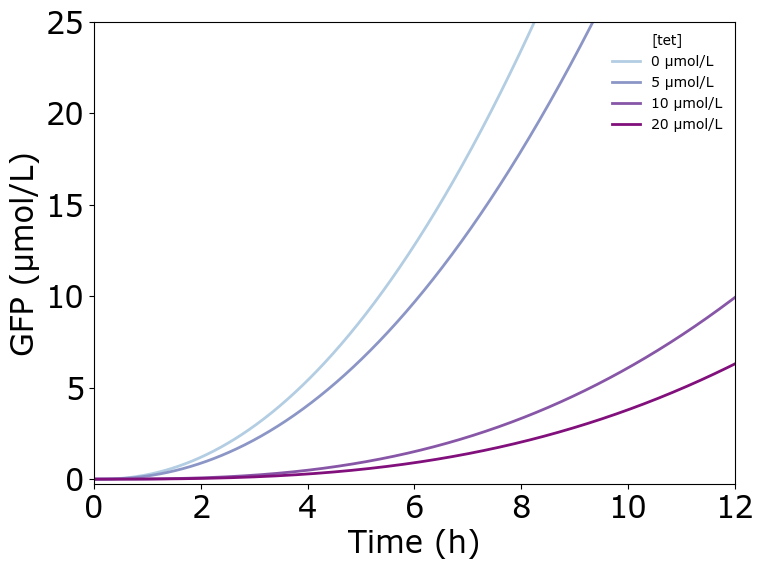

In [7]:
# Plot
for tet_conc, color in zip([0, 5, 10, 20], colors):
    # Reset the initial concentration of the inducer to 0
    m.set_species({"tet": tet_conc})
    R = py_simulate_model(Model=m, timepoints=timepoints)
# 
    # Plot each line and collect handles/ labels for the legend
    plt.plot(R['time'] /3600, R['GFP'], color=color, linewidth=2, label=f"{tet_conc} μmol/L")

# Format plot function call (assuming it sets some formatting properties)
FormatPlot('GFP (μmol/L)', 'BioSCRAPE_NOTgateTL_rnadeg')

# Model 3: Extension with Upstream LacI Regulation

**Model 3 = Model 2 + upstream LacI Regulation**

Added reactions:

 * D_unreg + LacI $\leftrightarrow$ LacID
 * LacI + IPTG $\leftrightarrow$ LacI-IPTG

 ***Note:** Regulation to $D_{unreg}$ was introduced, but name of species was unchanged.*

In [8]:
# Adding regulation to LacI-IPTG `D_unreg` using the same 

# Create new reactions
m.create_reaction(["D_unreg","LacI"], ["LacID"], "massaction", {"k":"k_rep_T"})
m.create_reaction(["LacID"], ["D_unreg","LacI"], "massaction", {"k":"k_derep_T"})

m.create_reaction(["LacI","IPTG"], ["LacI-IPTG"], "massaction", {"k":"k_ind_T"})
m.create_reaction( ["LacI-IPTG"], ["LacI","IPTG"],"massaction", {"k":"k_unin_T"})

# Set species
m.set_species({"LacI": 5})

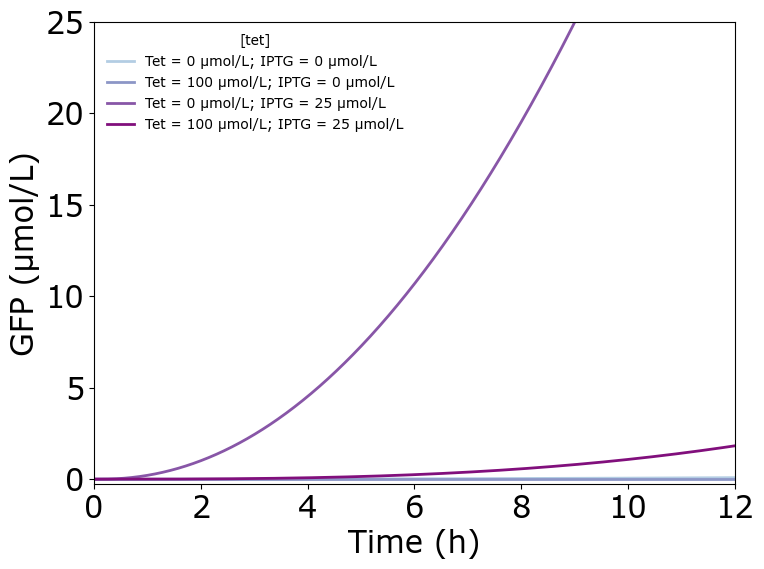

In [9]:
# Plot

for conc_tet, conc_iptg, color in zip([0, 100, 0, 100], [0, 0, 25, 25], colors):
    # Reset the initial concentration of the inducer to 0
    m.set_species({"tet": conc_tet})
    m.set_species({"IPTG": conc_iptg})
    R = py_simulate_model(Model=m, timepoints=timepoints)

    # Plot each line and collect handles/ labels for the legend
    plt.plot(R['time'] /3600, R['GFP'], color=color, linewidth=2, label=f"Tet = {conc_tet} μmol/L; IPTG = {conc_iptg} μmol/L")
plt.legend()


# Format plot function call
FormatPlot('GFP (μmol/L)', 'BioSCRAPE_NOTgateTL_rnadeg_reg')

# Computing environment

In [10]:
%load_ext watermark
%watermark -v -p bioscrape,bokeh,jupyterlab,biocrnpyler

Python implementation: CPython
Python version       : 3.12.12
IPython version      : 9.12.0

bioscrape  : 1.2.1
bokeh      : 3.9.1
jupyterlab : 4.5.0
biocrnpyler: 1.3.2

